# 07 — Performance de Vendedores
**Olist Analytics Hub | Etapa 7 de 7**

**Objetivo:** Avaliar os vendedores do marketplace — quem concentra a receita, quem entrega bem, quem derruba a experiência do cliente — e resumir isso num score único para priorizar ações.

---
### Perguntas que este notebook responde
1. Quão concentrada é a receita entre os vendedores?
2. O vendedor que posta atrasado é responsável pelo atraso ao cliente?
3. Como combinar avaliação, pontualidade e volume num score?
4. Quantos vendedores pararam de vender?

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from IPython.display import display

from src.data_loader import load_raw_dataset
from src.data_cleaner import load_processed, save_processed, clean_order_items
from src.visualizations import setup_style, save_fig, format_brl
from src.config import COLORS

setup_style()
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print('✓ Ambiente configurado.')

✓ Ambiente configurado.


## 1. Base de Itens por Vendedor

O `orders_enriched` tem uma linha por pedido, mas um pedido pode ter itens de vendedores diferentes. Por isso parto da tabela de itens e trago do fact table as informações do pedido (entrega e avaliação).

In [2]:
df = load_processed('orders_enriched')
itens = clean_order_items(load_raw_dataset('order_items'))
vendedores = load_raw_dataset('sellers')

pedidos_entregues = df[df['is_delivered'] & df['delivery_days'].notna()]
colunas_pedido = ['order_id', 'order_purchase_timestamp', 'order_delivered_carrier_date',
                  'delivered_on_time', 'delivery_delay_days', 'review_score', 'customer_state']

base = itens.merge(pedidos_entregues[colunas_pedido], on='order_id', how='inner')

# O vendedor tem um prazo para entregar o pacote à transportadora (shipping_limit_date)
base['postou_atrasado'] = base['order_delivered_carrier_date'] > base['shipping_limit_date']

# Uma linha por par pedido × vendedor, para não contar o mesmo pedido várias vezes
pedido_vendedor = base.drop_duplicates(['order_id', 'seller_id'])

print(f'Itens: {len(base):,}')
print(f'Pares pedido × vendedor: {len(pedido_vendedor):,}')
print(f'Vendedores com vendas entregues: {base["seller_id"].nunique():,}')

Itens: 110,189
Pares pedido × vendedor: 97,811
Vendedores com vendas entregues: 2,970


## 2. Concentração de Receita

In [3]:
por_vendedor = (
    base.groupby('seller_id')
    .agg(
        receita=('price', 'sum'),
        itens=('order_item_id', 'count'),
        primeira_venda=('order_purchase_timestamp', 'min'),
        ultima_venda=('order_purchase_timestamp', 'max'),
    )
    .join(
        pedido_vendedor.groupby('seller_id').agg(
            pedidos=('order_id', 'count'),
            nota_media=('review_score', 'mean'),
            taxa_no_prazo=('delivered_on_time', 'mean'),
            taxa_postagem_atrasada=('postou_atrasado', 'mean'),
        )
    )
    .join(vendedores.set_index('seller_id')[['seller_city', 'seller_state']])
    .sort_values('receita', ascending=False)
)

acumulado = por_vendedor['receita'].cumsum() / por_vendedor['receita'].sum() * 100
pct_vendedores = np.arange(1, len(por_vendedor) + 1) / len(por_vendedor) * 100

top_1pct = acumulado.iloc[int(len(por_vendedor) * 0.01) - 1]
top_20pct = acumulado.iloc[int(len(por_vendedor) * 0.20) - 1]
print(f'Pedidos por vendedor — mediana: {por_vendedor["pedidos"].median():.0f}, máximo: {por_vendedor["pedidos"].max():,}')
print(f'Top 1% dos vendedores ({int(len(por_vendedor) * 0.01)}): {top_1pct:.1f}% da receita')
print(f'Top 20% dos vendedores: {top_20pct:.1f}% da receita')

Pedidos por vendedor — mediana: 7, máximo: 1,819
Top 1% dos vendedores (29): 25.5% da receita
Top 20% dos vendedores: 82.3% da receita


  ✓ Figura salva: 07_concentracao_vendedores.png


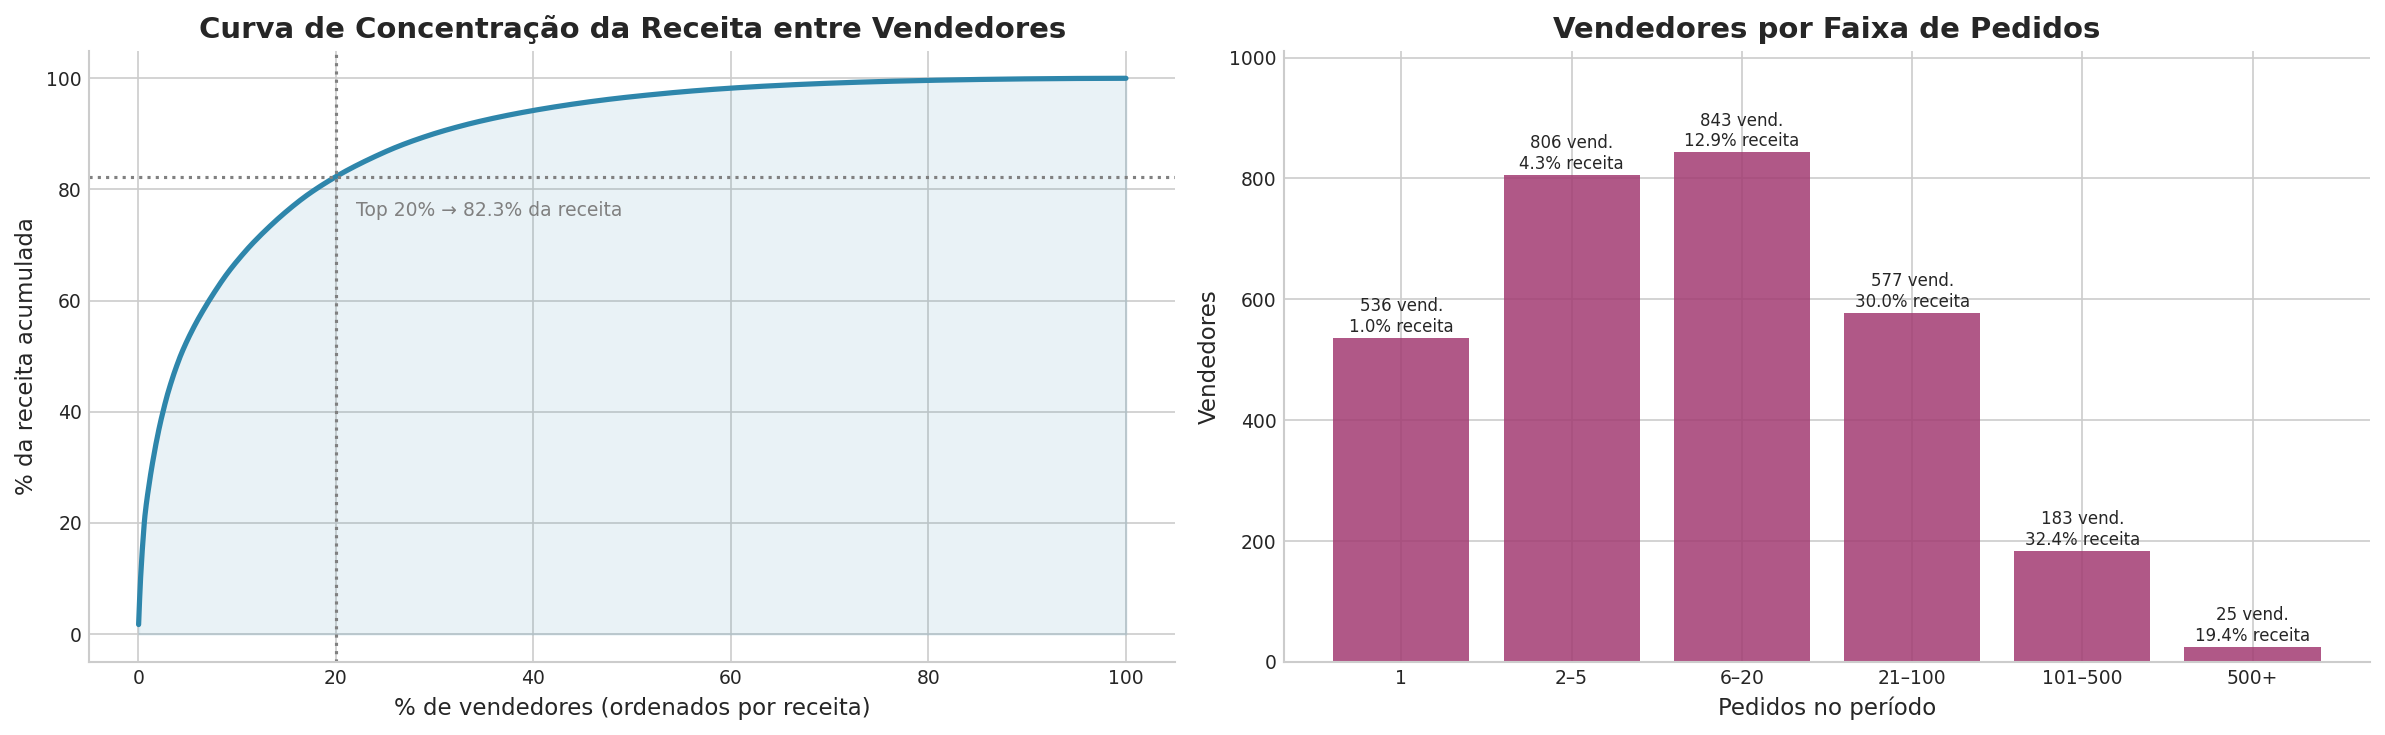

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(pct_vendedores, acumulado.values, color=COLORS['primary'], linewidth=2.5)
axes[0].fill_between(pct_vendedores, acumulado.values, alpha=0.1, color=COLORS['primary'])
axes[0].axvline(20, color='gray', linestyle=':', linewidth=1.5)
axes[0].axhline(top_20pct, color='gray', linestyle=':', linewidth=1.5)
axes[0].text(22, top_20pct - 7, f'Top 20% → {top_20pct:.1f}% da receita', fontsize=9, color='gray')
axes[0].set_title('Curva de Concentração da Receita entre Vendedores')
axes[0].set_xlabel('% de vendedores (ordenados por receita)')
axes[0].set_ylabel('% da receita acumulada')

bins = [0, 1, 5, 20, 100, 500, np.inf]
rotulos = ['1', '2–5', '6–20', '21–100', '101–500', '500+']
faixas = pd.cut(por_vendedor['pedidos'], bins=bins, labels=rotulos)
resumo_faixas = por_vendedor.groupby(faixas, observed=True).agg(vendedores=('receita', 'size'), receita=('receita', 'sum'))
resumo_faixas['pct_receita'] = resumo_faixas['receita'] / resumo_faixas['receita'].sum() * 100

axes[1].bar(resumo_faixas.index.astype(str), resumo_faixas['vendedores'], color=COLORS['secondary'], alpha=0.85)
for i, (n, pr) in enumerate(zip(resumo_faixas['vendedores'], resumo_faixas['pct_receita'])):
    axes[1].text(i, n + 10, f'{n:,} vend.\n{pr:.1f}% receita', ha='center', fontsize=8)
axes[1].set_title('Vendedores por Faixa de Pedidos')
axes[1].set_xlabel('Pedidos no período')
axes[1].set_ylabel('Vendedores')
axes[1].set_ylim(0, resumo_faixas['vendedores'].max() * 1.2)

plt.tight_layout()
save_fig('07_concentracao_vendedores')
plt.show()

## 3. Postagem Atrasada × Atraso ao Cliente

O atraso que o cliente sente pode vir do vendedor (que demora a postar) ou da transportadora. Comparando a data em que o pacote chegou à transportadora com o prazo de postagem, dá para separar as duas coisas.

In [5]:
efeito_postagem = (
    pedido_vendedor
    .groupby('postou_atrasado')
    .agg(
        pedidos=('order_id', 'count'),
        pct_atraso_cliente=('delivered_on_time', lambda s: (1 - s.mean()) * 100),
        nota_media=('review_score', 'mean'),
    )
    .rename(index={False: 'Postou no prazo', True: 'Postou atrasado'})
)
display(efeito_postagem.round(2))

atraso_total = (~pedido_vendedor['delivered_on_time']).sum()
atraso_com_postagem = (~pedido_vendedor['delivered_on_time'] & pedido_vendedor['postou_atrasado']).sum()
print(f'Dos pedidos que chegaram atrasados ao cliente, {atraso_com_postagem / atraso_total:.1%} tiveram postagem atrasada pelo vendedor.')

,pedidos,pct_atraso_cliente,nota_media
postou_atrasado,,,
Postou no prazo,89036,5.97,4.18
Postou atrasado,8775,22.85,3.69


Dos pedidos que chegaram atrasados ao cliente, 27.4% tiveram postagem atrasada pelo vendedor.


## 4. Score Composto de Vendedores

Para o score considero apenas vendedores com **pelo menos 20 pedidos** — com menos que isso, uma única avaliação ruim distorce a média. Cada componente vira um percentil (0 a 100) entre esses vendedores, e o score é uma média ponderada:

| Componente | Métrica | Peso |
|---|---|---|
| Avaliação | nota média dos pedidos | 40% |
| Pontualidade | % de pedidos entregues ao cliente no prazo | 40% |
| Volume | número de pedidos (log) | 20% |

Volume pesa menos de propósito: a ideia é premiar quem entrega uma boa experiência, não só quem vende muito.

In [6]:
MIN_PEDIDOS = 20
PESOS = {'avaliacao': 0.4, 'pontualidade': 0.4, 'volume': 0.2}

elegiveis = por_vendedor[por_vendedor['pedidos'] >= MIN_PEDIDOS].copy()
elegiveis['p_avaliacao'] = elegiveis['nota_media'].rank(pct=True) * 100
elegiveis['p_pontualidade'] = elegiveis['taxa_no_prazo'].rank(pct=True) * 100
elegiveis['p_volume'] = np.log1p(elegiveis['pedidos']).rank(pct=True) * 100
elegiveis['score'] = (
    PESOS['avaliacao'] * elegiveis['p_avaliacao']
    + PESOS['pontualidade'] * elegiveis['p_pontualidade']
    + PESOS['volume'] * elegiveis['p_volume']
)
elegiveis['faixa_score'] = pd.qcut(elegiveis['score'], 4, labels=['Q1 (pior)', 'Q2', 'Q3', 'Q4 (melhor)'])

print(f'Vendedores elegíveis: {len(elegiveis):,} de {len(por_vendedor):,} '
      f'({elegiveis["receita"].sum() / por_vendedor["receita"].sum():.1%} da receita)')

colunas_exibir = ['seller_state', 'pedidos', 'receita', 'nota_media', 'taxa_no_prazo', 'taxa_postagem_atrasada', 'score']
formato = {'pedidos': '{:,.0f}', 'receita': 'R$ {:,.0f}', 'nota_media': '{:.2f}', 'taxa_no_prazo': '{:.1%}',
           'taxa_postagem_atrasada': '{:.1%}', 'score': '{:.1f}'}

print('\nTop 10 vendedores pelo score:')
display(elegiveis.nlargest(10, 'score')[colunas_exibir].style.format(formato))

print('Bottom 10 vendedores pelo score:')
display(elegiveis.nsmallest(10, 'score')[colunas_exibir].style.format(formato))

Vendedores elegíveis: 804 de 2,970 (82.4% da receita)

Top 10 vendedores pelo score:


,seller_state,pedidos,receita,nota_media,taxa_no_prazo,taxa_postagem_atrasada,score
seller_id,,,,,,,
12b9676b00f60f3b700e83af21824c0e,RS,133,"R$ 26,376",4.55,98.5%,0.8%,88.4
289cdb325fb7e7f891c38608bf9e0962,SP,109,"R$ 13,411",4.59,98.2%,0.9%,87.8
c3cfdc648177fdbbbb35635a37472c53,PR,278,"R$ 43,048",4.47,97.8%,1.1%,87.1
6cd68b3ed6d59aaa9fece558ad360c0a,MG,149,"R$ 11,189",4.46,98.7%,0.0%,86.5
744dac408745240a2c2528fb1b6028f3,PR,78,"R$ 22,323",4.58,98.7%,3.8%,86.3
e882b2a25a10b9c057cc49695f222c19,RJ,57,"R$ 51,058",4.58,100.0%,10.5%,86.2
0ea22c1cfbdc755f86b9b54b39c16043,MG,234,"R$ 10,592",4.41,99.1%,2.1%,86.0
725c32fa80c2faacc4fc88450d27314e,SP,89,"R$ 7,839",4.52,98.9%,0.0%,85.6
ac3508719a1d8f5b7614b798f70af136,RS,101,"R$ 12,446",4.64,97.0%,1.0%,85.5


Bottom 10 vendedores pelo score:


,seller_state,pedidos,receita,nota_media,taxa_no_prazo,taxa_postagem_atrasada,score
seller_id,,,,,,,
054694fa03fe82cec4b7551487331d74,SP,20,"R$ 8,286",3.40,70.0%,60.0%,1.5
1dfe5347016252a7884b694d4f10f5c4,SP,20,"R$ 1,632",3.40,75.0%,0.0%,1.8
4e5725ba188db8252977a4f0227bd462,SP,21,"R$ 1,865",3.52,71.4%,4.8%,2.8
ff69aa92bb6b1bf9b8b7a51c2ed9cf8b,SP,20,"R$ 21,941",3.65,75.0%,0.0%,3.1
821fb029fc6e495ca4f08a35d51e53a5,SP,24,"R$ 17,852",3.48,62.5%,0.0%,3.8
f76a3b1349b6df1ee875d1f3fa4340f0,SP,24,"R$ 4,161",3.46,66.7%,37.5%,3.8
7f152321c60a266edc53af1925ef96c1,SC,20,"R$ 3,920",3.80,70.0%,15.0%,4.7
f08c008c8a8d31417763738a1788a2a8,PR,20,"R$ 1,212",3.42,85.0%,0.0%,4.8
e99e927c81e3f51739c94fcdfca9f10f,MG,21,"R$ 2,598",3.71,81.0%,4.8%,5.2


In [7]:
por_quartil = (
    elegiveis
    .groupby('faixa_score', observed=True)
    .agg(
        vendedores=('score', 'size'),
        receita=('receita', 'sum'),
        nota_media=('nota_media', 'mean'),
        taxa_no_prazo=('taxa_no_prazo', 'mean'),
        taxa_postagem_atrasada=('taxa_postagem_atrasada', 'mean'),
    )
)
por_quartil['pct_receita'] = por_quartil['receita'] / por_quartil['receita'].sum() * 100
display(por_quartil.round(3))

,vendedores,receita,nota_media,taxa_no_prazo,taxa_postagem_atrasada,pct_receita
faixa_score,,,,,,
Q1 (pior),201,"1,971,631.69",3.83,0.86,0.15,18.10
Q2,202,"3,088,157.01",4.11,0.92,0.10,28.35
Q3,201,"3,378,321.86",4.25,0.95,0.07,31.01
Q4 (melhor),200,"2,455,575.45",4.46,0.98,0.04,22.54


  ✓ Figura salva: 07_score_vendedores.png


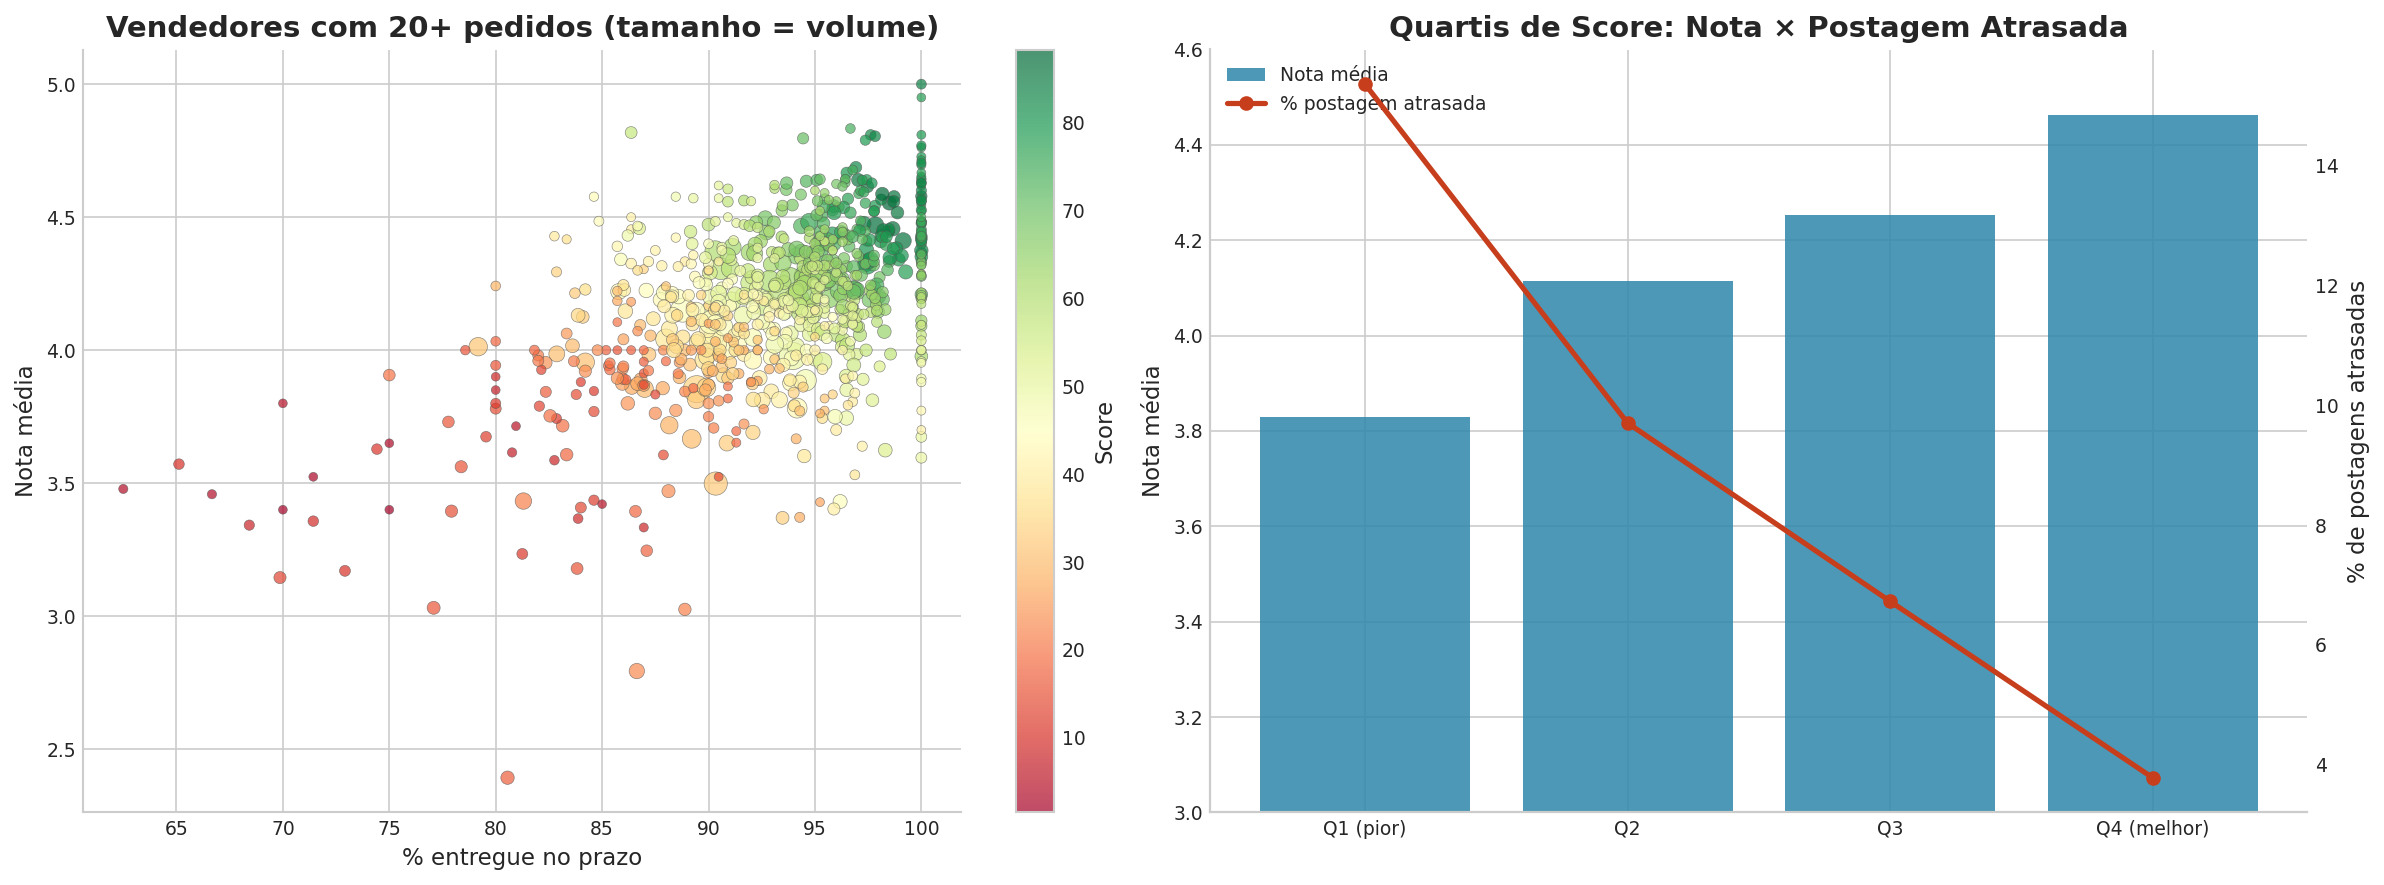

Spearman — postagem atrasada × nota do vendedor: -0.39 (p-valor = 6.2e-30)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc = axes[0].scatter(elegiveis['taxa_no_prazo'] * 100, elegiveis['nota_media'],
                     s=np.sqrt(elegiveis['pedidos']) * 4, c=elegiveis['score'],
                     cmap='RdYlGn', alpha=0.7, edgecolor='#555555', linewidth=0.3)
plt.colorbar(sc, ax=axes[0], label='Score')
axes[0].set_title(f'Vendedores com {MIN_PEDIDOS}+ pedidos (tamanho = volume)')
axes[0].set_xlabel('% entregue no prazo')
axes[0].set_ylabel('Nota média')

axes[1].bar(por_quartil.index.astype(str), por_quartil['nota_media'], color=COLORS['primary'], alpha=0.85, label='Nota média')
ax2 = axes[1].twinx()
ax2.plot(por_quartil.index.astype(str), por_quartil['taxa_postagem_atrasada'] * 100,
         color=COLORS['success'], linewidth=2.5, marker='o', label='% postagem atrasada')
ax2.set_ylabel('% de postagens atrasadas')
ax2.grid(False)
axes[1].set_ylim(3, 4.6)
axes[1].set_title('Quartis de Score: Nota × Postagem Atrasada')
axes[1].set_ylabel('Nota média')
linhas = axes[1].get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
rotulos_leg = axes[1].get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
axes[1].legend(linhas, rotulos_leg, loc='upper left')

plt.tight_layout()
save_fig('07_score_vendedores')
plt.show()

corr_postagem = stats.spearmanr(elegiveis['taxa_postagem_atrasada'], elegiveis['nota_media'])
print(f'Spearman — postagem atrasada × nota do vendedor: {corr_postagem.statistic:.2f} (p-valor = {corr_postagem.pvalue:.1e})')

## 5. Vendedores que Pararam de Vender

O dataset não informa se um vendedor saiu da plataforma. Uso uma aproximação: vendedor **inativo** é quem não teve nenhuma venda entregue nos últimos 90 dias do período.

In [9]:
DIAS_INATIVO = 90
fim_periodo = base['order_purchase_timestamp'].max()
por_vendedor['dias_sem_vender'] = (fim_periodo - por_vendedor['ultima_venda']).dt.days
por_vendedor['inativo'] = por_vendedor['dias_sem_vender'] > DIAS_INATIVO

inativos_faixa = por_vendedor.groupby(faixas, observed=True)['inativo'].mean() * 100
print(f'Vendedores inativos (> {DIAS_INATIVO} dias sem vender): {por_vendedor["inativo"].mean():.1%}')
print(f'Entre os elegíveis ao score ({MIN_PEDIDOS}+ pedidos): {por_vendedor.loc[elegiveis.index, "inativo"].mean():.1%}')
print('\n% de inativos por faixa de pedidos:')
for faixa, pct in inativos_faixa.items():
    print(f'  {faixa:>8} pedidos: {pct:.1f}%')

elegiveis['inativo'] = por_vendedor.loc[elegiveis.index, 'inativo']
print('\n% de inativos por quartil de score:')
for q, pct in (elegiveis.groupby('faixa_score', observed=True)['inativo'].mean() * 100).items():
    print(f'  {q:<12} {pct:.1f}%')

Vendedores inativos (> 90 dias sem vender): 39.4%
Entre os elegíveis ao score (20+ pedidos): 16.9%

% de inativos por faixa de pedidos:
         1 pedidos: 64.9%
       2–5 pedidos: 48.3%
      6–20 pedidos: 36.1%
    21–100 pedidos: 19.1%
   101–500 pedidos: 10.4%
      500+ pedidos: 0.0%

% de inativos por quartil de score:
  Q1 (pior)    21.4%
  Q2           16.3%
  Q3           10.9%
  Q4 (melhor)  19.0%


  ✓ Figura salva: 07_vendedores_inativos.png


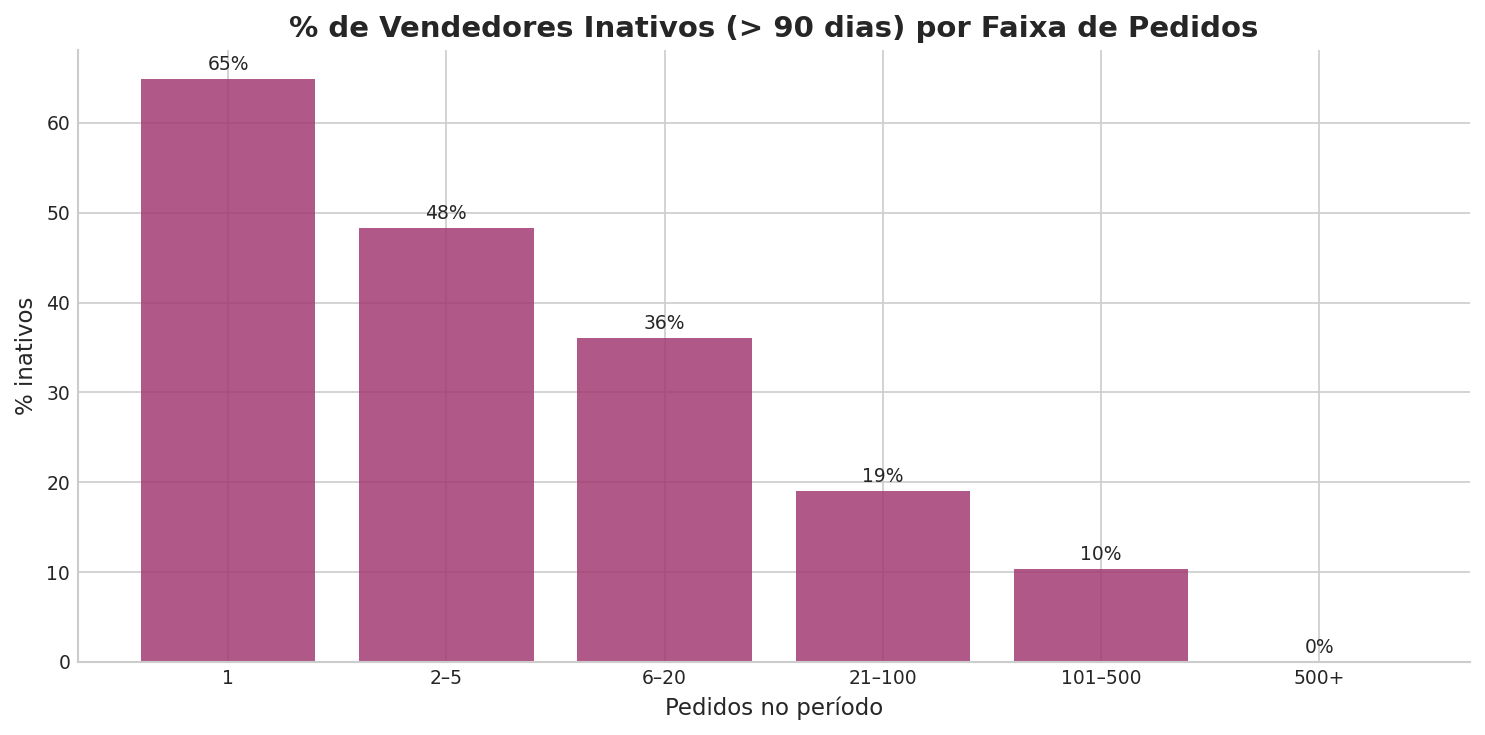

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(inativos_faixa.index.astype(str), inativos_faixa.values, color=COLORS['secondary'], alpha=0.85)
for i, v in enumerate(inativos_faixa.values):
    ax.text(i, v + 1, f'{v:.0f}%', ha='center', fontsize=9)
ax.set_title(f'% de Vendedores Inativos (> {DIAS_INATIVO} dias) por Faixa de Pedidos')
ax.set_xlabel('Pedidos no período')
ax.set_ylabel('% inativos')
plt.tight_layout()
save_fig('07_vendedores_inativos')
plt.show()

## 6. Salvando a Performance dos Vendedores

In [11]:
saida = por_vendedor.join(elegiveis[['score', 'faixa_score']]).reset_index()
saida['faixa_score'] = saida['faixa_score'].astype(str).replace('nan', None)
save_processed(saida, 'seller_performance')

  ✓ Salvo: data/processed/seller_performance.parquet (2,970 linhas)


## 7. Sumário e Insights

| Métrica | Valor |
|---------|-------|
| Vendedores com vendas entregues | 2.970 (mediana de 7 pedidos cada) |
| Concentração | top 1% (29 vendedores) = 25,5% da receita; top 20% = 82,3% |
| Postagem atrasada → atraso ao cliente | 22,9% dos pedidos, contra 6,0% quando o vendedor posta no prazo |
| Nota — postou no prazo × atrasado | 4,18 × 3,69 |
| Atrasos ao cliente com culpa (também) do vendedor | 27,4% |
| Vendedores no score (20+ pedidos) | 804, que somam 82,4% da receita |
| Vendedores inativos (> 90 dias sem vender) | 39,4% no total; 16,9% entre os do score |

### O que eu tiro daqui
- **A receita depende de poucos vendedores.** 25 vendedores com mais de 500 pedidos fazem quase 20% da receita. Perder um deles pesa mais do que perder centenas de vendedores pequenos.
- **Postar atrasado quase quadruplica a chance de o cliente receber atrasado.** Mas a maior parte dos atrasos (cerca de 73%) acontece mesmo com a postagem em dia — ou seja, a transportadora e a estimativa de prazo explicam mais o problema do que os vendedores.
- **O score separa bem os grupos:** do pior para o melhor quartil, a nota média sobe de 3,83 para 4,46 e a postagem atrasada cai de 15% para 4%. Os vendedores do pior quartil ainda movimentam 18% da receita entre os avaliados — são o alvo natural para acompanhamento.
- **Muitos vendedores param cedo.** 65% dos que fizeram só uma venda estão inativos; entre os que passaram de 100 pedidos, só cerca de 10%. Os primeiros pedidos parecem ser o momento crítico para reter vendedor.

### Limitações
- Os pesos do score (40/40/20) são uma escolha minha, não saíram dos dados. Mudar os pesos muda o ranking, então o score serve para priorizar, não como verdade absoluta.
- "Inativo" é uma aproximação: o dataset não diz se o vendedor saiu da plataforma, e o período termina em agosto de 2018.
- Quando um pedido tem itens de mais de um vendedor, a nota e a pontualidade do pedido são atribuídas a todos eles.

---
**Fim da série de notebooks.** Os resultados alimentam o dashboard em `dashboard/app.py`.